# Instagram Post Performance and Engagement - EDA

Goal : To find out how Instagram posts perform and what type of content people like the most

In [1]:
# Required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the Dataframe

og_df = pd.read_csv(r'Instagram_Analytics.csv')

In [3]:
# created a copy of dataframe

df = og_df.copy()

In [4]:
print('First 5 rows of the dataframe')
df.head()

First 5 rows of the dataframe


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
0,IG0000001,7,brand,3551.0,reel,Technology,Home Feed,1,30-11-2024 06:00,30-11-2024,...,5.0,7,34.0,4327.0,6230.0,0.0385,899,100,7,medium
1,IG0000002,20,creator,31095.0,image,Fitness,Hashtags,1,15-08-2025 15:00,15-08-2025,...,10.0,21,68.0,7451.0,8268.0,0.0663,805,122,5,viral
2,IG0000003,15,brand,8167.0,reel,Beauty,Reels Feed,0,11-09-2025 16:00,11-09-2025,...,2.0,1,22.0,1639.0,2616.0,0.0531,758,115,8,high
3,IG0000004,11,creator,9044.0,carousel,Music,External,0,18-09-2025 03:00,18-09-2025,...,0.0,7,0.0,2877.0,3171.0,0.0309,402,115,7,medium
4,IG0000005,8,creator,15986.0,reel,Technology,Profile,0,21-03-2025 09:00,21-03-2025,...,8.0,5,21.0,5350.0,8503.0,0.0221,155,112,9,low


In [5]:
print('Last 5 rows of dataframe')
df.tail()

Last 5 rows of dataframe


,post_id,account_id,account_type,follower_count,media_type,content_category,traffic_source,has_call_to_action,post_datetime,post_date,...,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count,performance_bucket_label
29994,IG0029995,5,brand,10739.0,carousel,Travel,Reels Feed,0,18-12-2024 10:00,18-12-2024,...,1.0,2,5.0,1564.0,2493.0,0.0032,124,127,8,low
29995,IG0029996,3,brand,10018.0,image,Beauty,Hashtags,0,05-05-2025 15:00,05-05-2025,...,2.0,1,7.0,2042.0,2492.0,0.0209,310,114,12,low
29996,IG0029997,18,creator,7486.0,image,Photography,Explore,1,26-05-2025 10:00,26-05-2025,...,10.0,16,59.0,5887.0,7528.0,0.0558,223,115,4,high
29997,IG0029998,6,creator,10034.0,carousel,Technology,Explore,1,02-08-2025 19:00,02-08-2025,...,3.0,0,19.0,5372.0,6312.0,0.0333,978,124,4,medium
29998,IG0029999,9,creator,6916.0,image,Technology,Explore,1,15-04-2025 20:00,15-04-2025,...,1.0,1,5.0,4019.0,5678.0,0.0100,272,126,11,low


In [6]:
row , col = df.shape
print(f'Total Rows = {row}')
print(f'Total Columns = {col}')

Total Rows = 29999
Total Columns = 23


In [7]:
print(f'Dimensions of this dataframe : {df.ndim}')

Dimensions of this dataframe : 2


In [8]:
print('All column names :\n')
for col in df.columns:
    print('->',col)

All column names :

-> post_id
-> account_id
-> account_type
-> follower_count
-> media_type
-> content_category
-> traffic_source
-> has_call_to_action
-> post_datetime
-> post_date
-> post_hour
-> day_of_week
-> likes
-> comments
-> shares
-> saves
-> reach
-> impressions
-> engagement_rate
-> followers_gained
-> caption_length
-> hashtags_count
-> performance_bucket_label


In [9]:
print('Detailed info of the dataframe :\n')
df.info()

Detailed info of the dataframe :

<class 'pandas.DataFrame'>
RangeIndex: 29999 entries, 0 to 29998
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   post_id                   29999 non-null  str    
 1   account_id                29999 non-null  int64  
 2   account_type              29999 non-null  str    
 3   follower_count            29995 non-null  float64
 4   media_type                29999 non-null  str    
 5   content_category          29999 non-null  str    
 6   traffic_source            29999 non-null  str    
 7   has_call_to_action        29999 non-null  int64  
 8   post_datetime             29999 non-null  str    
 9   post_date                 29999 non-null  str    
 10  post_hour                 29999 non-null  int64  
 11  day_of_week               29999 non-null  str    
 12  likes                     29998 non-null  float64
 13  comments                  29997 non-nu

In [10]:
# removed unwanted columns

df.drop(columns=['post_id','account_id'],inplace=True)

In [11]:
print('statistical info:\n')
df.describe()

statistical info:



,follower_count,has_call_to_action,post_hour,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count
count,29995.000000,29999.000000,29999.000000,29998.000000,29997.000000,29999.000000,29998.000000,29997.000000,29998.000000,29999.000000,29999.000000,29999.000000,29999.000000
mean,10278.955493,0.348778,11.499417,287.656710,8.522452,14.426614,42.517468,6272.692369,8467.013234,0.042107,502.152805,120.081169,7.987933
std,6692.037380,0.476592,6.900587,317.652516,10.116629,16.420899,47.809630,4985.970330,6826.006024,0.024095,290.364038,11.009108,2.828130
min,3083.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,268.000000,327.000000,0.000000,0.000000,70.000000,0.000000
25%,5824.000000,0.000000,6.000000,104.000000,3.000000,5.000000,15.000000,3058.000000,4102.000000,0.024000,251.000000,113.000000,6.000000
50%,9044.000000,0.000000,12.000000,199.000000,6.000000,10.000000,29.000000,4913.000000,6595.000000,0.040600,501.000000,120.000000,8.000000
75%,10739.000000,1.000000,17.000000,363.000000,11.000000,19.000000,54.000000,7863.000000,10620.750000,0.057000,755.000000,127.000000,10.000000
max,31095.000000,1.000000,23.000000,10632.000000,339.000000,516.000000,1542.000000,73339.000000,105203.000000,0.271000,1000.000000,166.000000,21.000000


In [12]:
# checking the null value 

print('Null value count -')
df.isnull().sum()

Null value count -


account_type                0
follower_count              4
media_type                  0
content_category            0
traffic_source              0
has_call_to_action          0
post_datetime               0
post_date                   0
post_hour                   0
day_of_week                 0
likes                       1
comments                    2
shares                      0
saves                       1
reach                       2
impressions                 1
engagement_rate             0
followers_gained            0
caption_length              0
hashtags_count              0
performance_bucket_label    0
dtype: int64

In [13]:
# Handling the null value 
for col in df.select_dtypes(include=['int','float']).columns:
    df[col] = df[col].fillna(df[col].mean())

In [14]:
print('Null percentage count - ')
df.isnull().mean()*100

Null percentage count - 


account_type                0.0
follower_count              0.0
media_type                  0.0
content_category            0.0
traffic_source              0.0
has_call_to_action          0.0
post_datetime               0.0
post_date                   0.0
post_hour                   0.0
day_of_week                 0.0
likes                       0.0
comments                    0.0
shares                      0.0
saves                       0.0
reach                       0.0
impressions                 0.0
engagement_rate             0.0
followers_gained            0.0
caption_length              0.0
hashtags_count              0.0
performance_bucket_label    0.0
dtype: float64

In [15]:
print(f'Total no. of duplicates : {df.duplicated().sum()}')

Total no. of duplicates : 0


In [16]:
print('Data types of all columns - ')
df.dtypes

Data types of all columns - 


account_type                    str
follower_count              float64
media_type                      str
content_category                str
traffic_source                  str
has_call_to_action            int64
post_datetime                   str
post_date                       str
post_hour                     int64
day_of_week                     str
likes                       float64
comments                    float64
shares                        int64
saves                       float64
reach                       float64
impressions                 float64
engagement_rate             float64
followers_gained              int64
caption_length                int64
hashtags_count                int64
performance_bucket_label        str
dtype: object

In [17]:
# chnaged the data types from str to datetime

df['post_datetime'] = pd.to_datetime(df['post_datetime'],dayfirst=True,errors='coerce')
df['post_date'] = pd.to_datetime(df['post_date'],dayfirst=True,errors='coerce')

df[['post_datetime','post_date']].dtypes

post_datetime    datetime64[us]
post_date        datetime64[us]
dtype: object

In [18]:
# column goruping by data types

num_col = df.select_dtypes(include=['int','float']).columns
cate_col = df.select_dtypes(include=['str']).columns
datetime_col = df.select_dtypes(include=['datetime']).columns


In [19]:
print('value count of every categorical columns - \n')

for col in cate_col:
    print(f'Column name: {col}')
    print(df[col].value_counts(),'\n')

value count of every categorical columns - 

Column name: account_type
account_type
creator    20944
brand       9055
Name: count, dtype: int64 

Column name: media_type
media_type
image       11927
carousel    10627
reel         7445
Name: count, dtype: int64 

Column name: content_category
content_category
Photography    3035
Fashion        3034
Technology     3025
Lifestyle      3017
Food           3010
Fitness        3004
Music          3003
Travel         2968
Beauty         2953
Comedy         2950
Name: count, dtype: int64 

Column name: traffic_source
traffic_source
Home Feed     5069
Hashtags      5063
Reels Feed    5026
External      5005
Profile       4962
Explore       4874
Name: count, dtype: int64 

Column name: day_of_week
day_of_week
Thursday     4351
Tuesday      4351
Wednesday    4341
Monday       4279
Saturday     4254
Friday       4218
Sunday       4205
Name: count, dtype: int64 

Column name: performance_bucket_label
performance_bucket_label
viral     7500
high    

In [20]:
print('Total number of unique values in each columns -\n')
for col in df.columns:
    print(f'{col}  : {df[col].nunique()}')

Total number of unique values in each columns -

account_type  : 2
follower_count  : 21
media_type  : 3
content_category  : 10
traffic_source  : 6
has_call_to_action  : 2
post_datetime  : 8475
post_date  : 366
post_hour  : 24
day_of_week  : 7
likes  : 1586
comments  : 111
shares  : 157
saves  : 378
reach  : 11966
impressions  : 14316
engagement_rate  : 1243
followers_gained  : 1001
caption_length  : 87
hashtags_count  : 22
performance_bucket_label  : 4


In [21]:
# Chcecking correlation 

df[num_col].corr()

,follower_count,has_call_to_action,post_hour,likes,comments,shares,saves,reach,impressions,engagement_rate,followers_gained,caption_length,hashtags_count
follower_count,1.000000,-0.001885,0.002863,-0.001975,-0.002976,-0.004933,-0.002591,0.002232,0.001258,-0.005631,0.012583,0.000375,0.006229
has_call_to_action,-0.001885,1.000000,0.009808,-0.002209,0.001142,-0.002239,-0.000792,0.006017,0.007457,-0.007044,0.001480,0.010685,-0.000983
post_hour,0.002863,0.009808,1.000000,0.001383,-0.001003,-0.003399,-0.001050,0.006988,0.006824,-0.007065,0.002142,0.010828,0.004060
likes,-0.001975,-0.002209,0.001383,1.000000,0.909748,0.944660,0.947844,0.738399,0.722726,0.506086,-0.005260,0.003162,0.006162
comments,-0.002976,0.001142,-0.001003,0.909748,1.000000,0.886241,0.886353,0.689982,0.674090,0.451598,-0.005694,0.002456,0.004251
shares,-0.004933,-0.002239,-0.003399,0.944660,0.886241,1.000000,0.920925,0.715800,0.699671,0.468681,-0.002571,0.004931,0.006597
saves,-0.002591,-0.000792,-0.001050,0.947844,0.886353,0.920925,1.000000,0.722131,0.706514,0.478117,-0.003138,0.000719,0.009258
reach,0.002232,0.006017,0.006988,0.738399,0.689982,0.715800,0.722131,1.000000,0.985506,0.006181,-0.004849,0.003442,0.002203
impressions,0.001258,0.007457,0.006824,0.722726,0.674090,0.699671,0.706514,0.985506,1.000000,-0.020674,-0.006192,0.003066,0.001794
engagement_rate,-0.005631,-0.007044,-0.007065,0.506086,0.451598,0.468681,0.478117,0.006181,-0.020674,1.000000,0.000509,0.000497,-0.001246


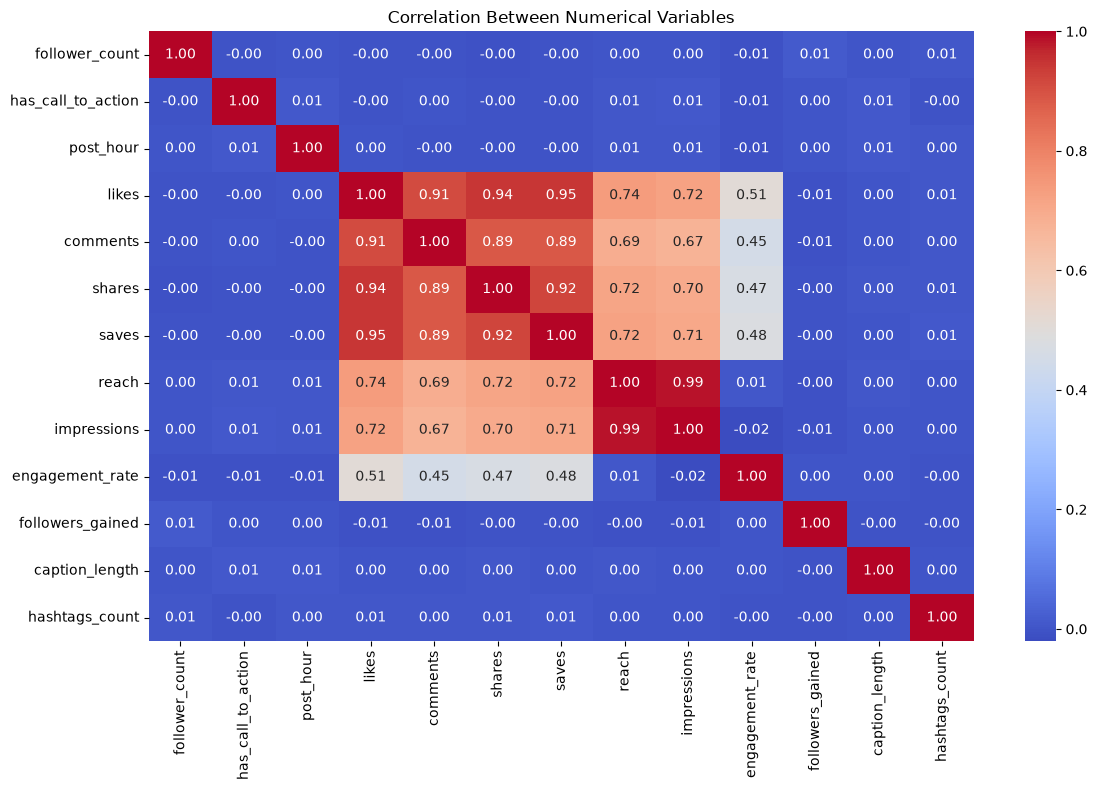

In [22]:
# Correlation Between Numerical Variables

plt.figure(figsize=(12, 8))

sns.heatmap(
    df[num_col].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

 Checking the outliers -



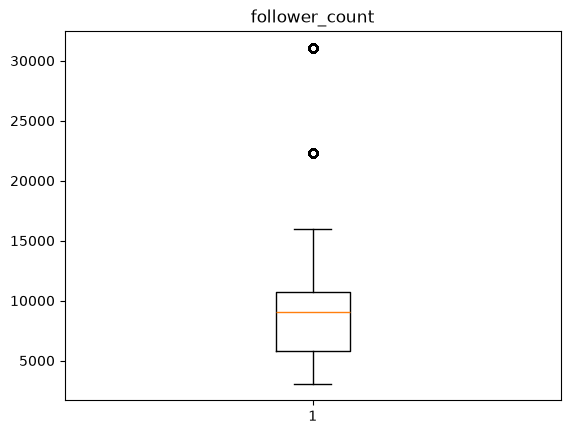

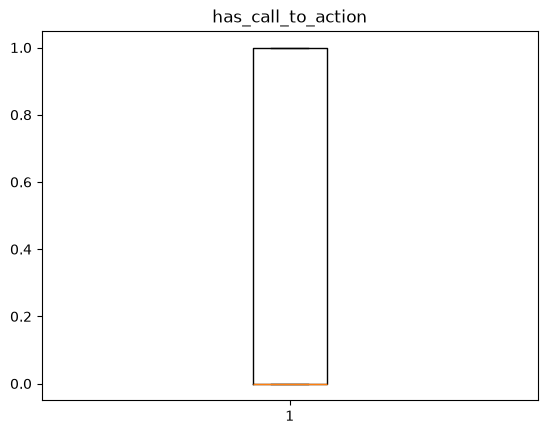

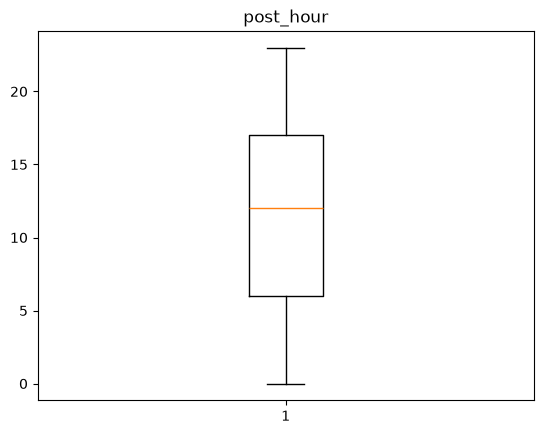

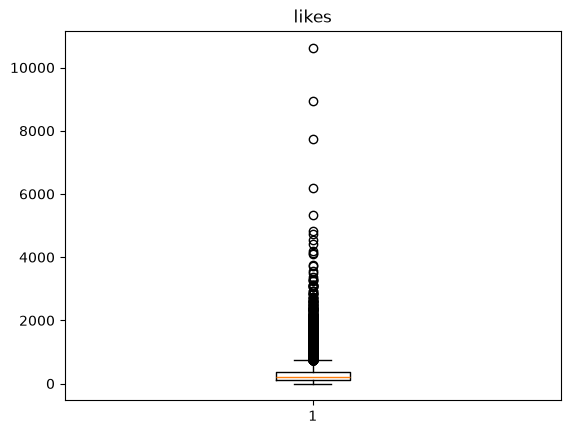

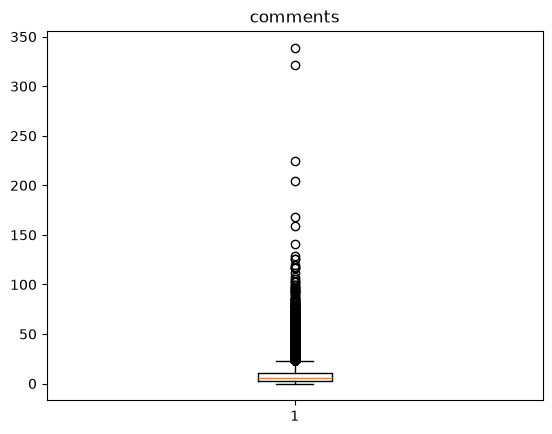

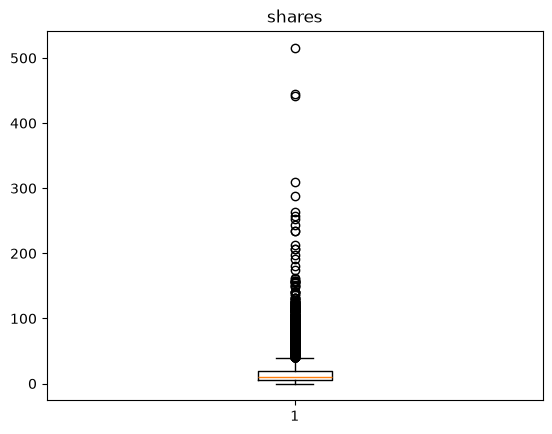

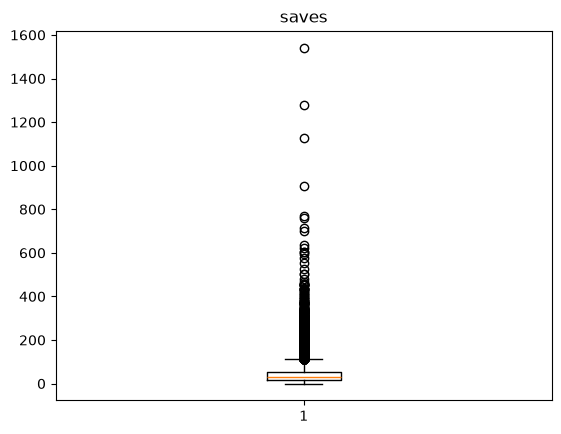

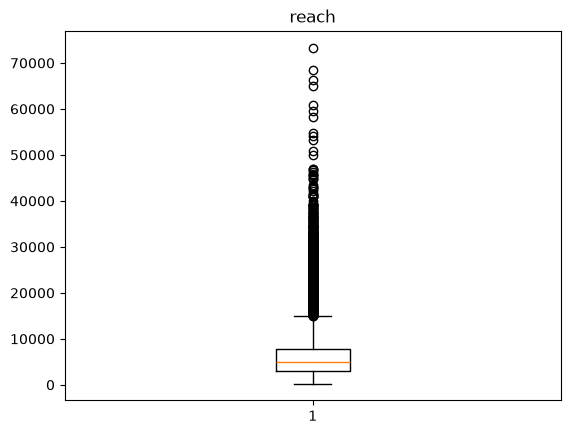

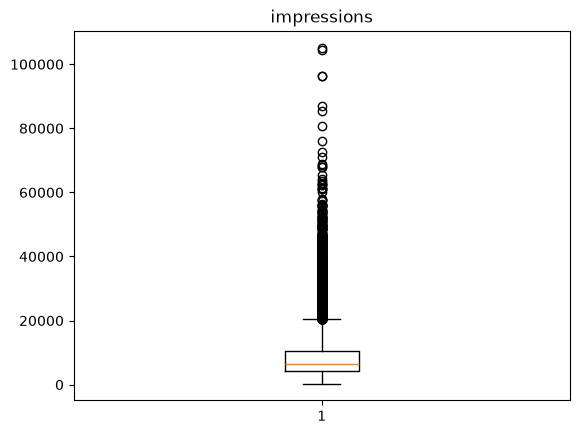

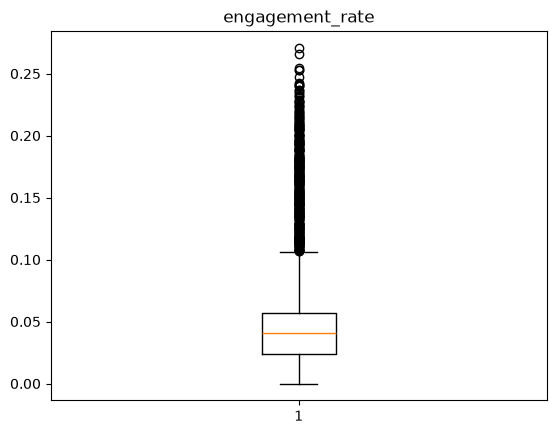

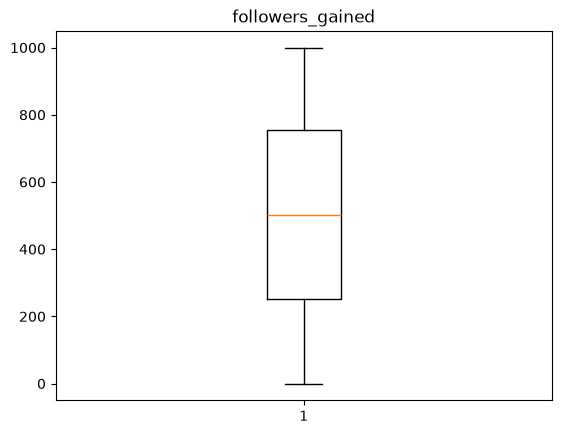

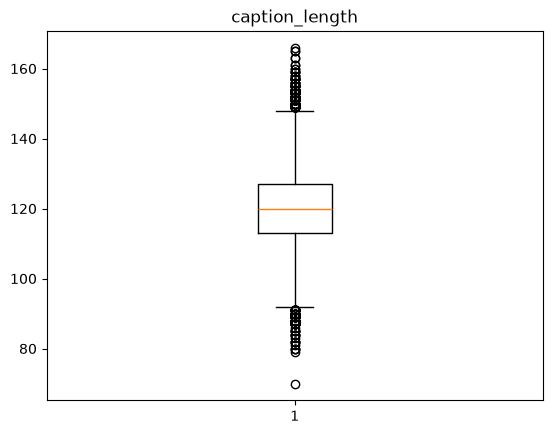

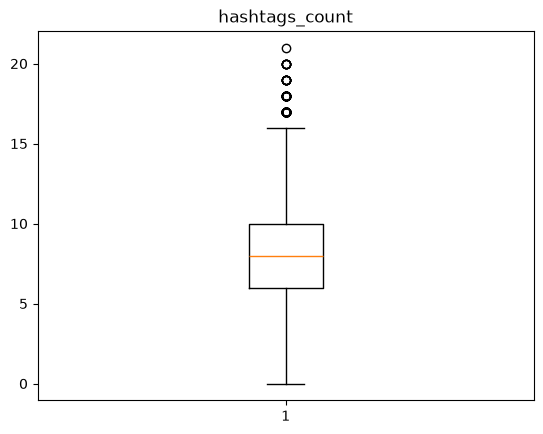

In [23]:
print(' Checking the outliers -\n')

for col in num_col:
    plt.boxplot(df[col])
    plt.title(col)
    plt.show()

In [24]:
for col in df.select_dtypes(include=['int','float']).columns.tolist():
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier = ((df[col] < lower) | (df[col] > upper))
    df.loc[outlier,col] = df[col].median()


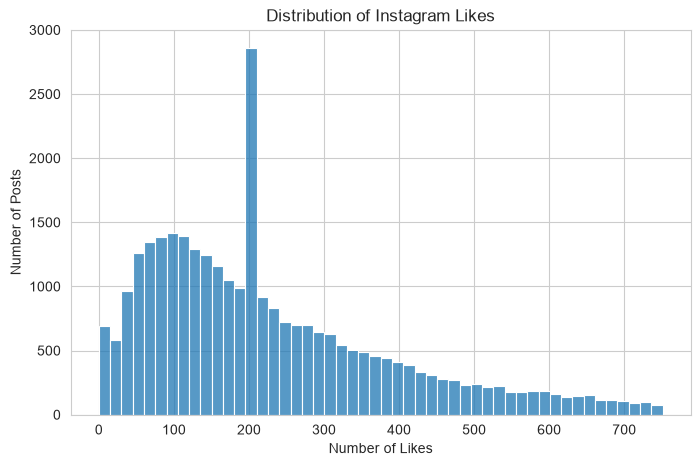

In [25]:
# Distribution of Instagram Likes

sns.set_style("whitegrid")
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="likes", bins=50)

plt.title("Distribution of Instagram Likes")
plt.xlabel("Number of Likes")
plt.ylabel("Number of Posts")

plt.show()

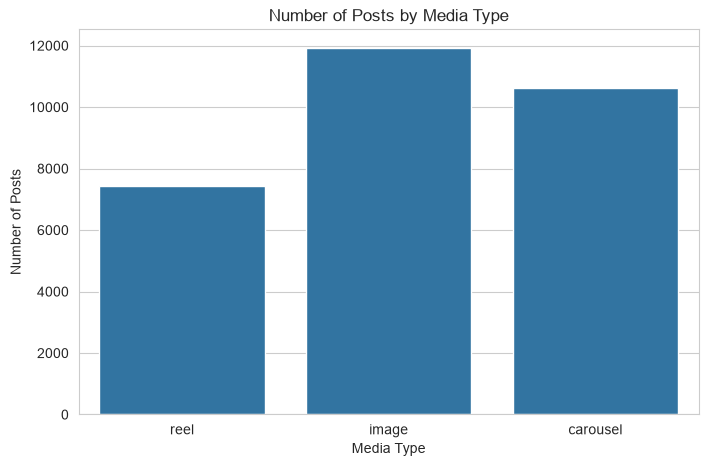

In [26]:
# Number of Posts by Media Type

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="media_type")

plt.title("Number of Posts by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Number of Posts")

plt.show()

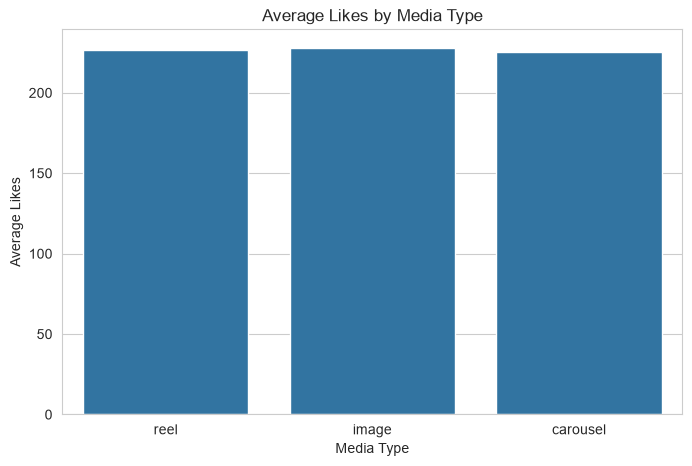

In [27]:
# Average Likes by Media Type

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="media_type",
    y="likes",
    errorbar=None
)

plt.title("Average Likes by Media Type")
plt.xlabel("Media Type")
plt.ylabel("Average Likes")

plt.show()

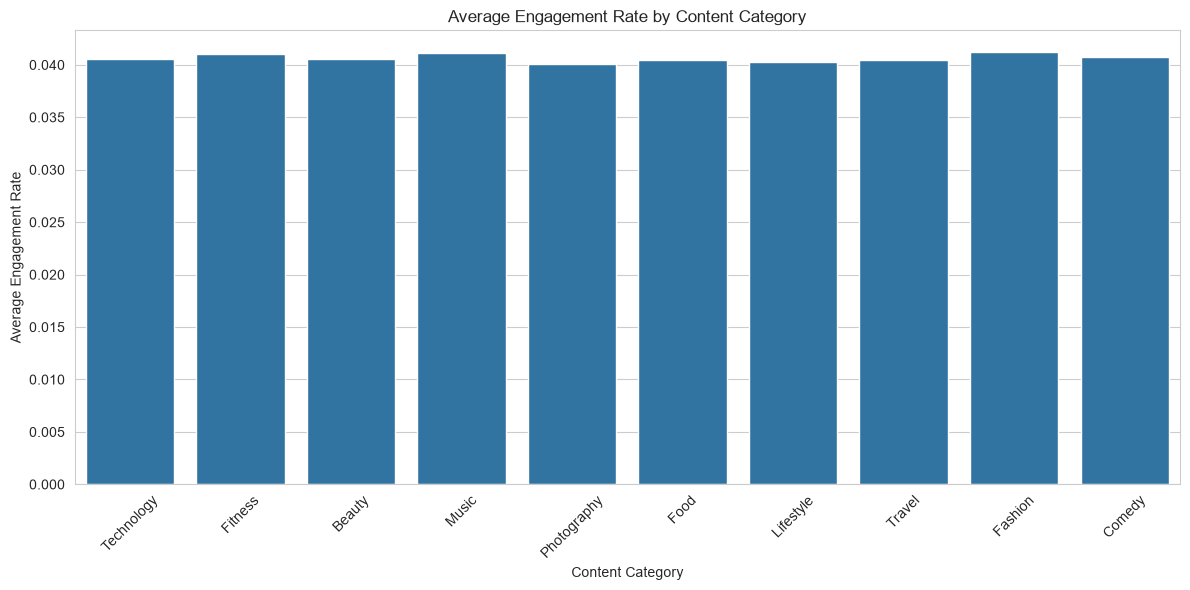

In [28]:
# Average Engagement Rate by Content Category

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="content_category",
    y="engagement_rate",
    errorbar=None
)

plt.title("Average Engagement Rate by Content Category")
plt.xlabel("Content Category")
plt.ylabel("Average Engagement Rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

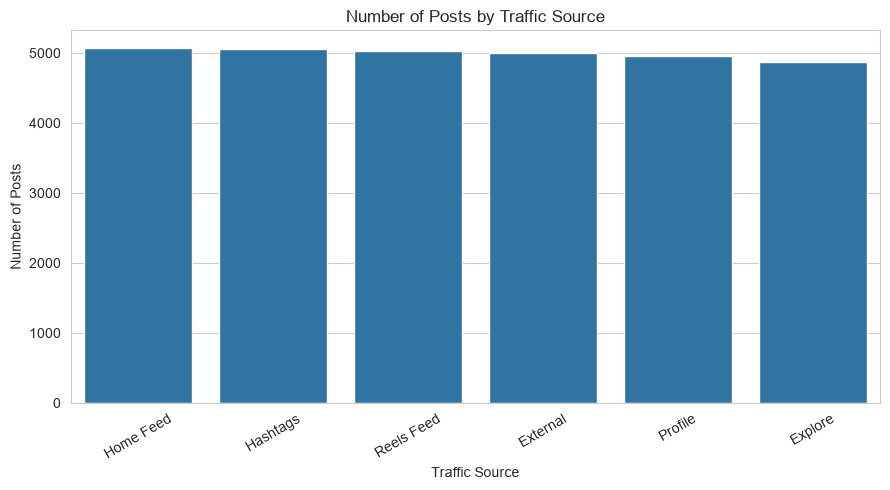

In [29]:
# Number of Posts by Traffic Source

plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="traffic_source")

plt.title("Number of Posts by Traffic Source")
plt.xlabel("Traffic Source")
plt.ylabel("Number of Posts")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

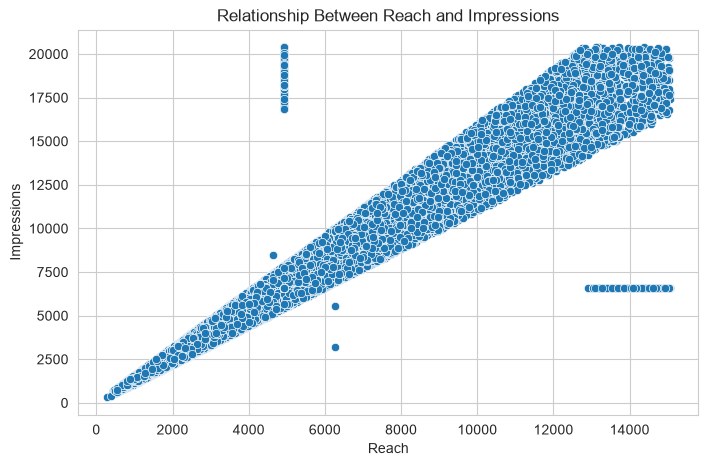

In [30]:
# Relationship Between Reach and Impression

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="reach",
    y="impressions"
)

plt.title("Relationship Between Reach and Impressions")
plt.xlabel("Reach")
plt.ylabel("Impressions")

plt.show()

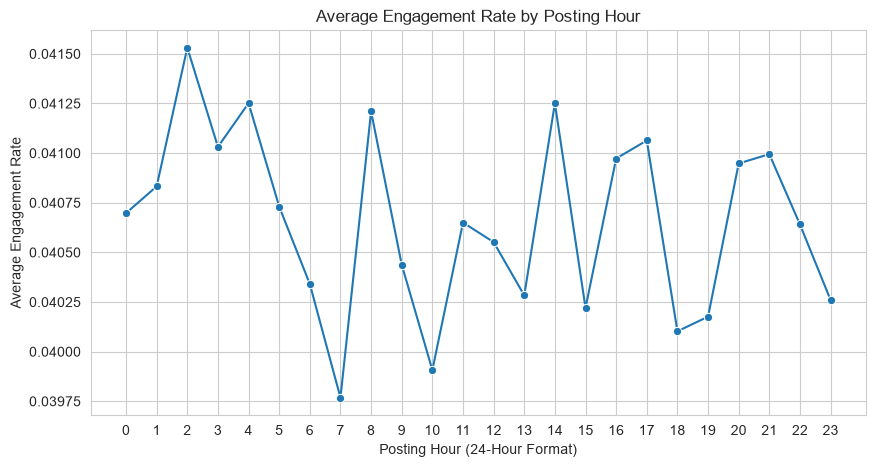

In [31]:
# Average Engagement Rate by Posting Hour

hourly_engagement = df.groupby("post_hour")["engagement_rate"].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=hourly_engagement.index,
    y=hourly_engagement.values,
    marker="o"
)

plt.title("Average Engagement Rate by Posting Hour")
plt.xlabel("Posting Hour (24-Hour Format)")
plt.ylabel("Average Engagement Rate")
plt.xticks(range(0, 24))

plt.show()